# Decision Tree Classification — Kaggle Social Network Ads

**Objective:** Predict whether a person purchases a product using **Age** and **EstimatedSalary**, then use **GridSearchCV** to find a better Decision Tree.

**Dataset:** [Social Network Ads on Kaggle](https://www.kaggle.com/datasets/rakeshrau/social-network-ads) — 400 records, with target `Purchased` (`0 = No`, `1 = Yes`).

### Learning sequence
1. Load and understand the dataset
2. Select features and target
3. Train/test split
4. Fit a baseline Decision Tree
5. Evaluate baseline with 5-fold cross-validation
6. Tune hyperparameters with `GridSearchCV`
7. Plot the best tree
8. Evaluate once on untouched test data
9. Predict for a new person

**Why only two features?** They allow us to understand the rules visually, without categorical encoding. We intentionally exclude `User ID` (identifier) and `Gender` (would require encoding). **No feature scaling is needed for a standard Decision Tree.**

## 1. Import libraries

We need Pandas for tabular data, Matplotlib for plotting, and scikit-learn for the model, tuning, and evaluation.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

## 2. Load the Kaggle dataset

**Recommended:** Download `Social_Network_Ads.csv` from the [Kaggle dataset page](https://www.kaggle.com/datasets/rakeshrau/social-network-ads) and put it in the **same folder** as this notebook.

If the file is not present, the next cell tries a public GitHub copy of the same dataset. Internet access is required for the fallback.

In [3]:
file = Path("Social_Network_Ads.csv")
df = pd.read_csv(file)

display(df.head())
print("Rows and columns:", df.shape)

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


Rows and columns: (400, 5)


## 3. Understand the data

Check whether any features are missing and count the two target classes. We will not use `User ID` because its numeric value does not represent buying behavior.

In [4]:
print("Missing values:")
print(df.isna().sum())
print("\nPurchased counts (0 = No, 1 = Yes):")
print(df["Purchased"].value_counts())

Missing values:
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

Purchased counts (0 = No, 1 = Yes):
Purchased
0    257
1    143
Name: count, dtype: int64


### Visualize the two input features

Each dot is one person. The dot color shows whether they bought the product.

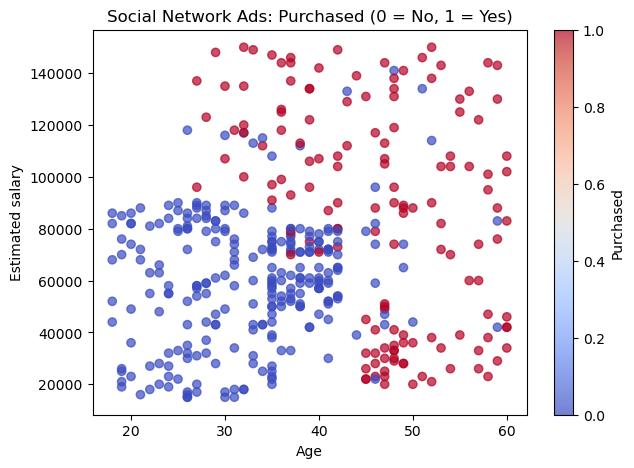

In [5]:
plt.figure(figsize=(7, 5))
plt.scatter(df["Age"], df["EstimatedSalary"],
            c=df["Purchased"], cmap="coolwarm", alpha=0.7)
plt.xlabel("Age")
plt.ylabel("Estimated salary")
plt.title("Social Network Ads: Purchased (0 = No, 1 = Yes)")
plt.colorbar(label="Purchased")
plt.show()

## 4. Select X (features) and y (target)

- `X` has two numeric input columns: Age and EstimatedSalary.
- `y` contains the answer to predict: Purchased.

In [6]:
X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (400, 2)
y shape: (400,)


## 5. Train/test split

- **80% training data:** used for fitting and hyperparameter tuning.
- **20% test data:** kept untouched until the very end.
- `stratify=y`: roughly preserves the class proportions in both parts.
- `random_state=42`: makes the split reproducible.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print("Training records:", len(X_train))
print("Test records:", len(X_test))

Training records: 320
Test records: 80


## 6. Train a baseline Decision Tree

We first fit a tree with default settings. The tree learns feature thresholds that reduce Gini impurity. A fully grown tree may overfit.

**Important:** We show **training accuracy** here, not test accuracy; the test set remains untouched.

In [8]:
baseline = DecisionTreeClassifier(random_state=42)
baseline.fit(X_train, y_train)

print("Baseline training accuracy:", round(baseline.score(X_train, y_train), 3))
print("Tree depth:", baseline.get_depth())
print("Number of leaves:", baseline.get_n_leaves())

Baseline training accuracy: 0.994
Tree depth: 11
Number of leaves: 46


## 7. Baseline accuracy using cross-validation

With `cv=5`, scikit-learn trains and validates five times on different parts of `X_train`. These are **validation scores**, not scores from our final `X_test`.

In [9]:
baseline_scores = cross_val_score(
    baseline, X_train, y_train, cv=5, scoring="accuracy"
)
print("Accuracy for each fold:", baseline_scores.round(3))
print("Mean baseline CV accuracy:", round(baseline_scores.mean(), 3))

Accuracy for each fold: [0.953 0.781 0.938 0.828 0.859]
Mean baseline CV accuracy: 0.872


## 8. Tune the model using GridSearchCV

GridSearchCV tries different combinations of Decision Tree settings and selects the combination with the **highest mean cross-validation accuracy**.

| Parameter | Why tune it? |
|---|---|
| `criterion` | Choose Gini impurity or entropy to evaluate splits |
| `max_depth` | Limit how many levels the tree can grow |
| `min_samples_leaf` | Prevent leaves containing too few training records |

`refit=True` fits the winning configuration once more on **all** `X_train`. The test set is not used to select parameters.

In [ ]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, None],
    "min_samples_leaf": [1, 2, 4, 6]
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    return_train_score=True,
    refit=True,
    n_jobs=1
)

grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print("Best mean CV accuracy:", round(grid.best_score_, 3))

Best parameters: {'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 1}
Best mean CV accuracy: 0.919


## 9. Compare hyperparameter combinations

- `mean_test_score` is the **mean validation accuracy across CV folds** (not the final test dataset).
- `mean_train_score` is the training accuracy, useful for checking overfitting.
- Larger gaps between training and validation accuracy may suggest overfitting.

In [11]:
results = pd.DataFrame(grid.cv_results_)
columns = ["param_criterion", "param_max_depth", "param_min_samples_leaf",
           "mean_train_score", "mean_test_score"]
display(results[columns].sort_values("mean_test_score", ascending=False).head(10).round(3))

,param_criterion,param_max_depth,param_min_samples_leaf,mean_train_score,mean_test_score
0,gini,2,1,0.923,0.919
1,gini,2,2,0.923,0.919
31,entropy,4,6,0.937,0.919
23,entropy,2,6,0.923,0.919
22,entropy,2,4,0.923,0.919
21,entropy,2,2,0.923,0.919
20,entropy,2,1,0.923,0.919
3,gini,2,6,0.923,0.919
2,gini,2,4,0.923,0.919
35,entropy,5,6,0.939,0.916


## 10. Visualize the best Decision Tree

`grid.best_estimator_` is the final model refitted with the best parameters. Each box shows a learned question, Gini impurity, samples, and class composition.

If the tree is deeper than 3, only the first three levels are shown to keep the plot readable.

Best tree depth: 2
Best tree leaves: 4


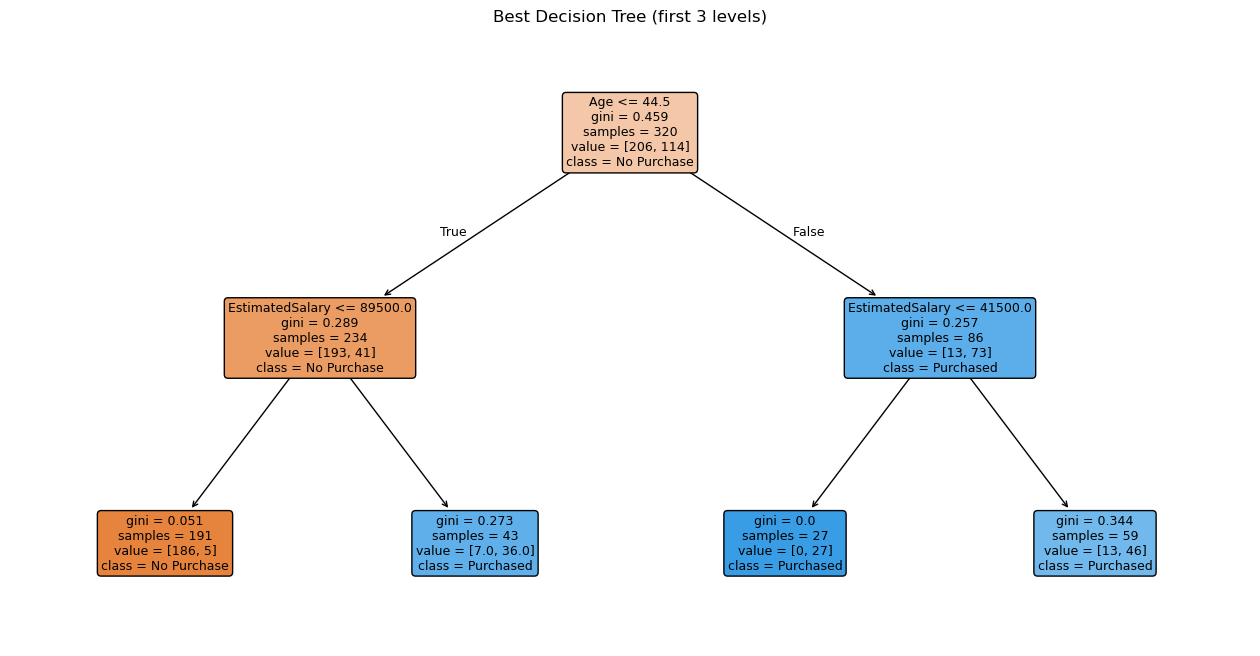

In [12]:
best_tree = grid.best_estimator_

print("Best tree depth:", best_tree.get_depth())
print("Best tree leaves:", best_tree.get_n_leaves())

plt.figure(figsize=(16, 8))
plot_tree(best_tree,
          feature_names=X.columns,
          class_names=["No Purchase", "Purchased"],
          filled=True, rounded=True,
          max_depth=3, fontsize=9)
plt.title("Best Decision Tree (first 3 levels)")
plt.show()

## 11. Evaluate the best model on the untouched test set

Now—and only now—we use `X_test` to estimate performance on unseen data. The **test accuracy may be lower or higher than CV accuracy**.

Test accuracy: 0.887

Classification report:
              precision    recall  f1-score   support

 No Purchase       0.94      0.88      0.91        51
   Purchased       0.81      0.90      0.85        29

    accuracy                           0.89        80
   macro avg       0.88      0.89      0.88        80
weighted avg       0.89      0.89      0.89        80



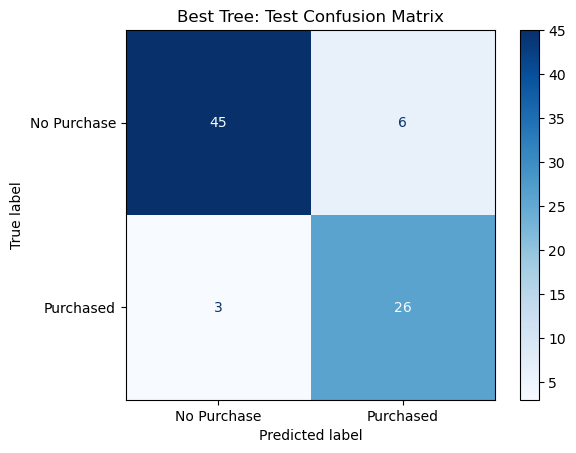

In [13]:
y_pred = best_tree.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No Purchase", "Purchased"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["No Purchase", "Purchased"],
    cmap="Blues"
)
plt.title("Best Tree: Test Confusion Matrix")
plt.show()

## 12. Predict for a new person

Try a person aged 42 with an estimated salary of 90,000. `predict()` returns the class; `predict_proba()` returns the leaf's class proportions (not necessarily calibrated probabilities).

In [14]:
new_person = pd.DataFrame({"Age": [42], "EstimatedSalary": [90000]})

prediction = best_tree.predict(new_person)[0]
probabilities = best_tree.predict_proba(new_person)[0]

print("Predicted class:", prediction, "(1 = Purchased, 0 = No Purchase)")
print("Class order:", best_tree.classes_)
print("Class probabilities:", probabilities.round(3))

Predicted class: 1 (1 = Purchased, 0 = No Purchase)
Class order: [0 1]
Class probabilities: [0.163 0.837]


## 13. Final review

**Main lesson:** A Decision Tree chooses feature thresholds to make child nodes purer. GridSearchCV helps choose tree complexity by comparing **validation accuracy**, not by looking at the final test data.

### Questions for students
1. Why did we exclude `User ID`?
2. Why do Decision Trees not usually need `StandardScaler`?
3. What is the difference between `max_depth=2` and `max_depth=None`?
4. Why is `grid.best_score_` **not** the final test accuracy?
5. What might it mean if training accuracy is 1.00 but CV accuracy is 0.80?

### Optional experiment
Add `"min_samples_split": [2, 5, 10]` to `param_grid`, rerun GridSearchCV, and compare the selected parameters and cross-validation accuracy.